# Week 7.3 - Smoothing, coarse correction, and the two-grid operator

Companion to Chapter 6, Section 6.3 and Problems 4, 5, 6.

Everything here is done with small dense matrices so that each statement of the chapter can be
checked exactly: the Galerkin coarse matrix, the projection property of coarse correction, the
optimal smoothing parameter $\omega=2/3$, and the mesh-independent contraction factor of the
two-grid operator.

## Helper routines

`poisson1d_dense` is the 1D Laplacian as a dense matrix (the grids here are tiny), `transfer`
builds $P$ and $R=\tfrac12P^\top$, and `smoother` builds $S=I-\omega D^{-1}A_h$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def poisson1d_dense(m):
    h = 1.0 / (m + 1)
    A = (np.diag(2 * np.ones(m)) - np.diag(np.ones(m - 1), 1)
         - np.diag(np.ones(m - 1), -1)) / h**2
    return A, h

def transfer(m):
    """Linear interpolation P (fine <- coarse) and full weighting R = P^T / 2."""
    mH = (m - 1) // 2
    P = np.zeros((m, mH))
    for j in range(mH):                      # coarse point j sits at fine index 2j+1
        c = 2 * j + 1
        P[c, j] = 1.0
        P[c - 1, j] = 0.5
        if c + 1 < m:
            P[c + 1, j] = 0.5
    return P, 0.5 * P.T

def smoother(A, omega):
    D = np.diag(np.diag(A))
    return np.eye(A.shape[0]) - omega * np.linalg.solve(D, A)

## (a), (b) Transfer operators and the Galerkin coarse matrix

$P$ is linear interpolation, $R=\tfrac12P^\top$ is full weighting with stencil
$\tfrac14(1,2,1)$. For the 1D Laplacian $A_H=RA_hP$ coincides *exactly* with the direct
discretisation on the grid of spacing $H=2h$ (Problem 4); using $P^\top$ instead of
$\tfrac12 P^\top$ scales the coarse operator by 2 and breaks that identity.

In [2]:
# ------------------------------------------------- (a) the transfer operators
m = 7
A, h = poisson1d_dense(m)
P, R = transfer(m)
print('(a) m = 7, h = 1/8, H = 2h = 1/4')
print('P^T =\n', P.T)
print('R   = P^T/2 applies the stencil (1,2,1)/4 :\n', R)
AH = R @ A @ P
AH_direct, H = poisson1d_dense((m - 1) // 2)
print('\n(b) A_H = R A_h P equals the direct coarse discretisation?',
      np.allclose(AH, AH_direct), '  (max diff %.2e)' % np.abs(AH - AH_direct).max())
print('    P^T A_h P = 2 A_H (wrong scaling): max diff %.2e'
      % np.abs(P.T @ A @ P - 2 * AH).max())

(a) m = 7, h = 1/8, H = 2h = 1/4
P^T =
 [[0.5 1.  0.5 0.  0.  0.  0. ]
 [0.  0.  0.5 1.  0.5 0.  0. ]
 [0.  0.  0.  0.  0.5 1.  0.5]]
R   = P^T/2 applies the stencil (1,2,1)/4 :
 [[0.25 0.5  0.25 0.   0.   0.   0.  ]
 [0.   0.   0.25 0.5  0.25 0.   0.  ]
 [0.   0.   0.   0.   0.25 0.5  0.25]]

(b) A_H = R A_h P equals the direct coarse discretisation? True   (max diff 0.00e+00)
    P^T A_h P = 2 A_H (wrong scaling): max diff 0.00e+00


## (c) Coarse correction alone is a projection

$T=I-PA_H^{-1}RA_h$ satisfies $T^2=T$, so its eigenvalues are $0$ and $1$ and $\rho(T)=1$
(Problem 5). Whatever the coarse space sees is removed in one step, whatever it does not see is
left untouched forever: coarse correction is not an iterative method on its own.

In [3]:
# ------------------------------------------- (c) coarse correction is a projection
T = np.eye(m) - P @ np.linalg.solve(AH, R @ A)
print('\n(c) T = I - P A_H^{-1} R A_h :  ||T^2 - T|| = %.2e,  rho(T) = %.4f,  rank T = %d  (m - m_H = %d)'
      % (np.abs(T @ T - T).max(), max(abs(np.linalg.eigvals(T))),
         np.linalg.matrix_rank(T), m - (m - 1) // 2))


(c) T = I - P A_H^{-1} R A_h :  ||T^2 - T|| = 0.00e+00,  rho(T) = 1.0000,  rank T = 4  (m - m_H = 4)


## (d) The smoothing factor

$\omega=1$ gives the smallest spectral radius of the smoother, yet it is the worst *smoother*:
the highest modes are barely damped. Minimising instead
$\rho_{\rm high}(\omega)=\max(|1-2\omega|,|1-\omega|)$ over the upper half of the spectrum
gives $\omega=\tfrac23$ and $\rho_{\rm high}=\tfrac13$ (Proposition 6.6).

In [4]:
# ----------------------------------------------- (d) the smoothing factor of omega
print('\n(d) weighted Jacobi, high-frequency damping rho_high(omega) = max(|1-2w|,|1-w|)')
for m_ in (7, 31):
    A_, _ = poisson1d_dense(m_)
    j = np.arange(1, m_ + 1)
    print('    m = %d' % m_)
    print('      omega   rho(S)    rho_high')
    for w in (0.5, 2 / 3, 0.8, 1.0):
        S_ = smoother(A_, w)
        mu = 1 - 2 * w * np.sin(j * np.pi / (2 * (m_ + 1)))**2
        hi = np.abs(mu[(m_ + 1) // 2 - 1:]).max()        # j >= (m+1)/2
        print('      %.3f   %.4f    %.4f' % (w, max(abs(np.linalg.eigvals(S_))), hi))
print('    omega = 1 minimises rho(S), but rho(S) is ~1 for every omega and decides nothing;')
print('    omega = 2/3 minimises the high-frequency factor, rho_high = 1/3, independently of m.')
print('    (the slides quote the m = 31 row, which is the one close to the theoretical')
print('     max(|1-2w|,|1-w|) = 0.5, 1/3, 0.6, 1)')


(d) weighted Jacobi, high-frequency damping rho_high(omega) = max(|1-2w|,|1-w|)
    m = 7
      omega   rho(S)    rho_high
      0.500   0.9619    0.5000
      0.667   0.9493    0.3333
      0.800   0.9391    0.5391
      1.000   0.9239    0.9239
    m = 31
      omega   rho(S)    rho_high
      0.500   0.9976    0.5000
      0.667   0.9968    0.3333
      0.800   0.9961    0.5961
      1.000   0.9952    0.9952
    omega = 1 minimises rho(S), but rho(S) is ~1 for every omega and decides nothing;
    omega = 2/3 minimises the high-frequency factor, rho_high = 1/3, independently of m.
    (the slides quote the m = 31 row, which is the one close to the theoretical
     max(|1-2w|,|1-w|) = 0.5, 1/3, 0.6, 1)


## (e) The two-grid contraction factor

$M_{\rm TG}=TS^\nu$ with $\omega=\tfrac23$. The spectral radius is $(1/3)^\nu$ for
$\nu=1,2$ and, crucially, does not change when the mesh is refined (Problem 6). Together with the
$\mathcal{O}(m)$ cost of a V-cycle this is what the word *optimal* means.

In [5]:
# ------------------------------------------------- (e) the two-grid operator
print('\n(e) two-grid operator M_TG = T S^nu, omega = 2/3')
print('       m      h       nu=1     nu=2     nu=3')
for m_ in (7, 15, 31, 63):
    A_, h_ = poisson1d_dense(m_)
    P_, R_ = transfer(m_)
    AH_ = R_ @ A_ @ P_
    T_ = np.eye(m_) - P_ @ np.linalg.solve(AH_, R_ @ A_)
    S_ = smoother(A_, 2 / 3)
    rr = [max(abs(np.linalg.eigvals(T_ @ np.linalg.matrix_power(S_, nu)))) for nu in (1, 2, 3)]
    print('    %4d  %.5f   %.4f   %.4f   %.4f' % (m_, h_, *rr))
print('    the contraction factor does not depend on h (contrast: Jacobi alone needs O(h^-2)')
print('    iterations), and rho(M_TG) ~ (1/3)^nu, the smoothing factor to the power nu.')


(e) two-grid operator M_TG = T S^nu, omega = 2/3
       m      h       nu=1     nu=2     nu=3
       7  0.12500   0.3333   0.1111   0.0741
      15  0.06250   0.3333   0.1111   0.0774
      31  0.03125   0.3333   0.1111   0.0785
      63  0.01562   0.3333   0.1111   0.0786
    the contraction factor does not depend on h (contrast: Jacobi alone needs O(h^-2)
    iterations), and rho(M_TG) ~ (1/3)^nu, the smoothing factor to the power nu.


## Damping per mode, and one smoothing + correction cycle

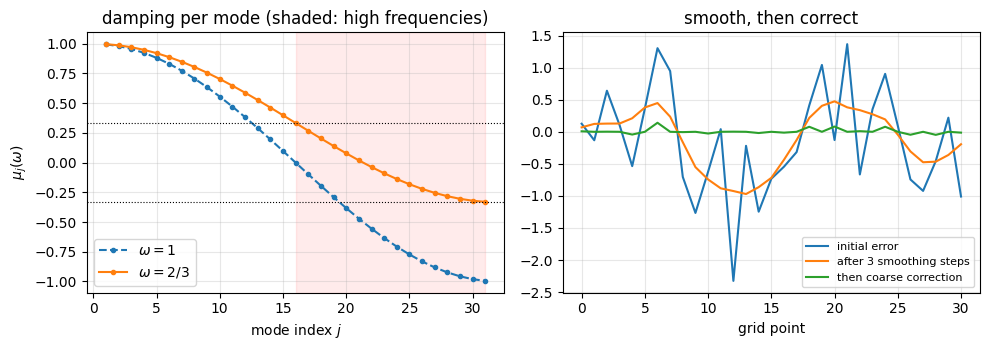

In [6]:
# ---------------------------------------------------------------- plot
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
m = 31
A, h = poisson1d_dense(m)
j = np.arange(1, m + 1)
for w, st in ((1.0, '--'), (2 / 3, '-')):
    ax[0].plot(j, 1 - 2 * w * np.sin(j * np.pi / (2 * (m + 1)))**2, st,
               marker='o', ms=3, label=r'$\omega=%s$' % ('1' if w == 1 else '2/3'))
ax[0].axvspan((m + 1) / 2, m, color='red', alpha=.08)
ax[0].axhline(1 / 3, color='k', lw=.8, ls=':'); ax[0].axhline(-1 / 3, color='k', lw=.8, ls=':')
ax[0].set_xlabel('mode index $j$'); ax[0].set_ylabel(r'$\mu_j(\omega)$')
ax[0].set_title('damping per mode (shaded: high frequencies)')
ax[0].legend(); ax[0].grid(alpha=.3)

P, R = transfer(m); AH = R @ A @ P
T = np.eye(m) - P @ np.linalg.solve(AH, R @ A)
S = smoother(A, 2 / 3)
rng = np.random.default_rng(0)
e = rng.standard_normal(m)
ax[1].plot(e, label='initial error')
ax[1].plot(np.linalg.matrix_power(S, 3) @ e, label=r'after 3 smoothing steps')
ax[1].plot(T @ np.linalg.matrix_power(S, 3) @ e, label='then coarse correction')
ax[1].set_xlabel('grid point'); ax[1].set_title('smooth, then correct')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()